# WF1 - Complete workflow: ParametricSimulation (ACCIM custom model)

WF1 runs a parametric study of the ACCIM custom adaptive model. A Latin hypercube sample of the slope `m` and intercept `n` of the comfort temperature, the offset of the setpoints and their upper applicability limit is drawn inside the band of published adaptive comfort models (m-n filter). After the annual simulations, every evaluation is screened against the ASHRAE 55 80 % acceptability band, using its hourly operative temperature.

The notebook follows Example 2 of the accim paper (parametric analysis of the custom model), with the sample building and weather files distributed with accim instead of the office building of the paper. The results are therefore similar in nature, not identical.

In practical terms, we will move through preparation, configuration, execution, and verification so every transition in the workflow stays explicit.
As the notebook progresses, each code cell is introduced with context first, then the call itself, and finally quick guidance on how to interpret the result.

Workflow roadmap:
- Preparation: imports, paths, run size and a lighter simulation setup (2 timesteps per hour, full-year run period).
- Configuration: a minimal set of hourly outputs, parameter ranges, the m-n filter and the LHS sample.
- Execution and review: annual simulations, results in kWh/m2 and parametric plots.
- Comfort screening: hourly indicators against ASHRAE 55 (80 % acceptability), a scatter matrix coloured by the outcome, the screening plot and the hourly adaptive comfort chart of two selected evaluations per climate.

Main classes, methods, and functions used in this notebook:
- `ParametricSimulation`
- `ef.get_building`
- `reduce_runtime`
- `modify_HVACmode`
- `parametric.discover_available_outputs`
- `parametric.select_outputs`
- `parametric.apply_outputs_preflight`
- `parametric.set_output_readers`
- `parametric.set_parameters`
- `parametric.set_mn_filter`
- `parametric.sampling_lhs`
- `parametric.plot_mn_filter`
- `ParametricSimulation.run_parametric_simulation`
- `parametric.set_building_floor_area`
- `parametric.compute_hourly_indicators`
- `parametric.plot_results_scatter_matrix`
- `parametric.plot_comfort_screening`
- `ParametricSimulation.get_hourly_df_parametric`
- `parametric.plot_adaptive_comfort_chart`

Narrative structure used in this notebook:
- Each code cell is preceded by an explanatory markdown block.
- Section headings are contextual to the current notebook and execution block.
- Key arguments are described before they are used in code.
- Execution-oriented cells may include a follow-up markdown note to help interpret results.

## WF1 custom parametric: import workflow dependencies

We start by loading every dependency required by the full workflow, so the remaining sections can run without hidden imports.

In this complete workflow notebook, imports are intentionally grouped in one place. That makes reruns in a fresh kernel predictable and easier to debug when versions change.

The cell also defines `show_plot_output`, a small helper that displays the figures and image files returned by the plotting methods.

What to verify right after running this cell:
- Review execution output and proceed when values look consistent with the workflow intent.

In [1]:
import os
from pathlib import Path

import pandas as pd
import accim
from besos import eppy_funcs as ef
from accim.parametric_and_optimisation.main import ParametricSimulation
from accim.parametric_and_optimisation.funcs_for_besos.param_accis import modify_HVACmode
from accim.parametric_and_optimisation.objectives import average_results, sum_results
from accim.utils import reduce_runtime

# (Run once per notebook)
%matplotlib inline
# If you prefer interaction (zoom/pan), use: %matplotlib widget
from IPython.display import Image, display
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 160)


def show_plot_output(plot_output, image_paths=None):
    # Optional deterministic image display for methods that return tabular data.
    if image_paths is not None:
        if isinstance(image_paths, (str, Path)):
            image_paths = [image_paths]
        for plot_path in image_paths:
            display(Image(filename=str(plot_path)))

    if isinstance(plot_output, dict):
        for plot_path in plot_output.values():
            display(Image(filename=str(plot_path)))
        return
    if isinstance(plot_output, (str, Path)):
        display(Image(filename=str(plot_output)))
        return
    if hasattr(plot_output, "fig"):
        display(plot_output.fig)
        plt.show()
        return
    if hasattr(plot_output, "savefig"):
        display(plot_output)
        plt.show()
        return
    if isinstance(plot_output, pd.DataFrame):
        display(plot_output)
        return
    raise TypeError(f"Unsupported plot output type: {type(plot_output)}")


## WF1 custom parametric: set project paths, weather files and run size

Here we declare the project assets (IDF, EPWs, and results folder) and the size of the run.

The IDF and EPW files are the sample files in this folder. If accim was installed with `pip install "accim[samples]"`, copy this folder to a working directory before running the notebook, so that the installed files are not modified; the results are written to `RESULTS_DIRNAME` inside it.

Key settings in this cell and why they matter:
- `N_SAMPLES`: number of LHS samples. Each sample is simulated with every EPW, so the run has `N_SAMPLES x len(epw_list)` annual simulations. The paper used 100 samples; 20 keep this example short, and the value can be raised for a smoother picture.
- `PROCESSES`: simulations run in parallel. Half of the logical CPUs is a safe default; reduce it if the computer becomes unresponsive.

Variables created in this cell:
- `PROJECT_ROOT`: reused in subsequent workflow blocks.
- `idf_list`: reused in subsequent workflow blocks.
- `epw_list`: reused in subsequent workflow blocks.
- `RESULTS_DIRNAME`: reused in subsequent workflow blocks.
- `N_SAMPLES`: reused in subsequent workflow blocks.
- `PROCESSES`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that the IDF and EPW files are found and that the number of simulations is what you expect.

In [2]:
PROJECT_ROOT = Path.cwd()

idf_list = [
    "OSM_TestResidentialUnit_v01_onlygeometry_SchNatVent_v2520_high_performance.idf",
]
epw_list = ["Sydney.epw", "Seville.epw"]
RESULTS_DIRNAME = "wf1_parametric_custom_results"

N_SAMPLES = 20
PROCESSES = max(1, (os.cpu_count() or 2) // 2)

print("IDF files found:", [(PROJECT_ROOT / idf).exists() for idf in idf_list])
print("EPW files found:", [(PROJECT_ROOT / epw).exists() for epw in epw_list])
print(f"Annual simulations: {N_SAMPLES} samples x {len(epw_list)} EPWs = {N_SAMPLES * len(epw_list)}, "
      f"{PROCESSES} in parallel")


IDF files found: [True]
EPW files found: [True, True]
Annual simulations: 20 samples x 2 EPWs = 40, 6 in parallel


## WF1 custom parametric: load the baseline IDF model and make the simulations lighter

Load the base building model used by subsequent runs.

This is where the baseline IDF is loaded for all downstream operations. Later cells reuse this object for output setup, parameterization, and execution. The changes below only affect the model in memory: the IDF file is not modified.

The simulations are made lighter while keeping annual results:
- `reduce_runtime(...)` sets 2 timesteps per hour (the model has 6), minimal shadowing and a lower limit of figures in the shadow overlap calculations. Its run period arguments keep the full year: by default, `reduce_runtime` shortens the run period to 1 January.
- `Run_Simulation_for_Sizing_Periods = "No"`: the design days are still used to size the HVAC system, but they are not simulated as additional environments. Otherwise, the annual results read after each simulation would also include the 7 design days of the sample model (8,928 hours instead of 8,760), and the HVAC electricity would be about 3 % higher.

Fewer timesteps make each simulation faster, with small differences in the annual energy compared with the 6 timesteps of the model. For final results, remove the `reduce_runtime(...)` call, but keep the sizing-period setting.

Variables created in this cell:
- `building`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that the printed messages report 2 timesteps per hour and MinimalShadowing.

In [3]:
building = ef.get_building(idf_list[0])

reduce_runtime(
    idf_object=building,
    minimal_shadowing=True,
    timesteps=2,
    runperiod_begin_month=1,
    runperiod_begin_day_of_month=1,
    runperiod_end_month=12,
    runperiod_end_day_of_month=31,
)
# Keep the design days out of the annual results.
building.idfobjects["SimulationControl"][0].Run_Simulation_for_Sizing_Periods = "No"


Solar distribution has been set to MinimalShadowing.
Shading Calculation Update Frequency was previously set to 20 days, and it has been modified to 20 days.
Maximum Figures in Shadow Overlap Calculations was previously set to 15000, and it has been modified to 200.
Number of Timesteps per Hour was previously set to 6, and it has been modified to 2.


## WF1 custom parametric: initialize parametric simulation object

At this point we instantiate the parametric engine that will coordinate outputs, parameters, and run plans.

From here onward, most workflow actions are methods on this object, which keeps the execution trace coherent. As in Example 2 of the paper, the building is fully air-conditioned: the VRF system without natural ventilation (`ScriptType="vrf_ac"`) and `HVACmode` 0.

Key arguments used in this cell and why they matter:
- `buildings`: loaded IDF model used in this workflow.
- `parameters_type`: parameter family used in the simulation setup.
- `epws`: list of EPW weather files used to run scenarios.
- `output_freqs`: time frequency requested for outputs; the comfort screening needs hourly values.
- `ScriptType`: `"vrf_ac"`, a VRF system for fully air-conditioned buildings.
- `modify_HVACmode(building, 0)`: fixes the operation to air conditioning only.

Variables created in this cell:
- `parametric`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm these objects are available for the next block: `parametric`.

In [4]:
parametric = ParametricSimulation(
    buildings=[building],
    parameters_type="accim custom model",
    epws=epw_list,
    output_freqs=["hourly"],
    ScriptType="vrf_ac",
)
modify_HVACmode(building, 0)



--------------------------------------------------------
Adaptive-Comfort-Control-Implemented Model (ACCIM) v0.7.8
--------------------------------------------------------

This tool allows to apply adaptive setpoint temperatures. 
For further information, please read the documentation: 
https://accim.readthedocs.io/en/master/
For a visual understanding of the tool, please visit the following jupyter notebooks:
-    Using addAccis() to apply adaptive setpoint temperatures
https://accim.readthedocs.io/en/master/jupyter_notebooks/addAccis/using_addAccis.html
-    Using rename_epw_files() to rename the EPWs for proper data analysis after simulation
https://accim.readthedocs.io/en/master/jupyter_notebooks/rename_epw_files/using_rename_epw_files.html
-    Using runEp() to directly run simulations with EnergyPlus
https://accim.readthedocs.io/en/master/jupyter_notebooks/runEp/using_runEp.html
-    Using the class Table() for data analysis
https://accim.readthedocs.io/en/master/jupyter_notebo

Generic contaminant setpoint: Always 0.5ppm Schedule has been added
Air distribution effectiveness (always 1) Schedule has been added
VRF Heating Cooling (Northern Hemisphere) Schedule has been added
DefaultFanEffRatioCurve Curve:Cubic Object has been added
VRFTUCoolCapFT Curve:Cubic Object has been added
VRFTUHeatCapFT Curve:Cubic Object has been added
VRFCoolCapFTBoundary Curve:Cubic Object has been added
VRFCoolEIRFTBoundary Curve:Cubic Object has been added
CoolingEIRLowPLR Curve:Cubic Object has been added
VRFHeatCapFTBoundary Curve:Cubic Object has been added
VRFHeatEIRFTBoundary Curve:Cubic Object has been added
HeatingEIRLowPLR Curve:Cubic Object has been added
DefaultFanPowerRatioCurve Curve:Exponent Object has been added
DXHtgCoilDefrostEIRFT Curve:Biquadratic Object has been added
VRFCoolCapFT Curve:Biquadratic Object has been added
VRFCoolCapFTHi Curve:Biquadratic Object has been added
VRFCoolEIRFT Curve:Biquadratic Object has been added
VRFCoolEIRFTHi Curve:Biquadratic Obj

AHST_Sch_Floor_2_Residential_Living_Occupants Schedule has been added
ACST_Sch_Floor_2_Residential_Living_Occupants Schedule has been added
Added - SetComfTemp Program
Added - CountHours_Floor_1_Residential_Living_Occupants Program
Added - CountHours_Floor_2_Residential_Living_Occupants Program
Added - SetAppLimits Program
Added - ApplyCAT Program
Added - SetAST_Master Program with 109 lines


Added - 46 per-ComfStand SetAST subprograms
Added - SetAST Program (base program that calls SetAST_Master)
Added - SetASTnoTol Program
Added - CountHoursNoApp_Floor_1_Residential_Living_Occupants Program
Added - SetGeoVarFloor_1_Residential_Living_Occupants Program
Added - CountHoursNoApp_Floor_2_Residential_Living_Occupants Program
Added - SetGeoVarFloor_2_Residential_Living_Occupants Program
Added - SetInputData Program
Added - Comfort Temperature Output Variable
Added - Adaptive Cooling Setpoint Temperature Output Variable
Added - Adaptive Heating Setpoint Temperature Output Variable
Added - Adaptive Cooling Setpoint Temperature_No Tolerance Output Variable
Added - Adaptive Heating Setpoint Temperature_No Tolerance Output Variable
Added - z_test_ComfStand Output Variable
Added - z_test_ACSTaul Output Variable
Added - z_test_ACSTall Output Variable
Added - z_test_AHSTaul Output Variable
Added - z_test_AHSTall Output Variable
Added - z_test_CAT Output Variable
Added - z_test_ACSToffse

## WF1 custom parametric: discover available outputs and select the minimal set

Before locking outputs, we scan what this model setup can actually report, and keep only the outputs the workflow uses. Hourly outputs are what make each simulation folder heavy, so the selection is kept small:
- meters `Electricity:HVAC`, `Heating:Electricity` and `Cooling:Electricity`, for the annual results and the hourly HVAC electricity;
- `Zone Operative Temperature` of each zone, for the annual mean and the comfort screening;
- `Zone Thermal Comfort ASHRAE 55 Adaptive Model Running Average Outdoor Air Temperature`, the running mean outdoor temperature calculated by EnergyPlus (accim adds the adaptive comfort models to the People objects). The screening takes it from the hourly outputs; it depends only on the weather file, so the column of one People object is enough.

Key arguments used in this cell and why they matter:
- `reduce_sim_time`: enables a fast scan mode when discovering outputs.
- `prefer`: preferred backend for output discovery.
- `meters`: energy meters to include as outputs.
- `variables`: output variables to include by name.
- `match`: matching rule used to select outputs (exact names, ignoring case).
- `on_missing`: `"raise"` stops here if a requested output is not available.

Variables created in this cell:
- `meter_names`: reused in subsequent workflow blocks.
- `hourly_variable_names`: reused in subsequent workflow blocks.
- `available_outputs`: reused in subsequent workflow blocks.
- `df_meters_sel`: reused in subsequent workflow blocks.
- `df_vars_sel`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Check that three meters and the operative temperature of every zone are selected, plus one running-mean column.
- Confirm the reported discovery source matches your preferred backend.

In [5]:
meter_names = ["Electricity:HVAC", "Heating:Electricity", "Cooling:Electricity"]
hourly_variable_names = [
    "Zone Operative Temperature",
    "Zone Thermal Comfort ASHRAE 55 Adaptive Model Running Average Outdoor Air Temperature",
]
available_outputs = parametric.discover_available_outputs(
    reduce_sim_time=True,
    prefer="testsimeplus",
)
print("Discovery source:", available_outputs["meta"].get("source"))

df_meters_sel = parametric.select_outputs(
    meters=meter_names,
    match="case_insensitive",
    on_missing="raise",
)["meters"]
df_vars_sel = parametric.select_outputs(
    variables=hourly_variable_names,
    match="case_insensitive",
    on_missing="raise",
)["variables"]

# The running mean is the same for every People object: keep the first one.
is_running_mean = df_vars_sel["variable_name"].str.contains("Running Average")
df_vars_sel = pd.concat(
    [df_vars_sel[~is_running_mean], df_vars_sel[is_running_mean].head(1)],
    ignore_index=True,
)
print(df_meters_sel[["key_name", "frequency"]].to_string(index=False))
print(df_vars_sel[["key_value", "variable_name", "frequency"]].to_string(index=False))


Solar distribution is already set to MinimalShadowing, therefore no action has been performed.
Shading Calculation Update Frequency was previously set to 20 days, and it has been modified to 20 days.
Maximum Figures in Shadow Overlap Calculations was previously set to 200, and it has been modified to 200.
Number of Timesteps per Hour was previously set to 2, and it has been modified to 2.


Discovery source: testsimeplus
           key_name frequency
   Electricity:HVAC    Hourly
Heating:Electricity    Hourly
Cooling:Electricity    Hourly
                           key_value                                                                         variable_name frequency
                        FLOOR_1_ZONE                                                            Zone Operative Temperature    Hourly
                        FLOOR_2_ZONE                                                            Zone Operative Temperature    Hourly
FLOOR_1 RESIDENTIAL LIVING OCCUPANTS Zone Thermal Comfort ASHRAE 55 Adaptive Model Running Average Outdoor Air Temperature    Hourly


## WF1 custom parametric: run output preflight checks before execution

This block applies preflight checks to the selected outputs before execution.

Preflight is the final schema gate; if this step is clean, output-related runtime errors are much less likely. With `clean_mode="all"`, the output objects of the IDF (37 output variables, the SQLite file and the summary tables of the sample model) are removed before the selection is added.

Key arguments used in this cell and why they matter:
- `df_meters_sel`: table of selected meters to apply to the IDF.
- `df_vars_sel`: table of selected variables to apply to the IDF.
- `clean_mode`: cleanup mode applied before adding outputs.
- `validate_before_apply`: whether to validate before editing the IDF.
- `validate_after_apply`: whether to validate after editing the IDF.
- `on_missing`: behavior when a requested output is missing.

Variables created in this cell:
- `preflight_report`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Verify that the verification reports no missing or extra outputs.

In [6]:
preflight_report = parametric.apply_outputs_preflight(
    df_meters_sel=df_meters_sel,
    df_vars_sel=df_vars_sel,
    clean_mode="all",
    validate_before_apply=False,
    validate_after_apply=True,
    on_missing="raise",
)
print(preflight_report["verification"])


{'vars': {'expected': 3, 'actual': 3, 'missing_in_idf': [], 'extra_in_idf': [], 'by_idf': {}}, 'meters': {'expected': 3, 'actual': 3, 'missing_in_idf': [], 'extra_in_idf': [], 'by_idf': {}}}


## WF1 custom parametric: define how the annual results are read

Now we register the readers that turn the hourly outputs of each simulation into the columns of the results table.

The meters are summed over the year (`sum_results`, J) and the operative temperature of each zone is averaged (`average_results`, °C). The running mean is only needed hourly, for the screening, so it has no reader.

Key arguments used in this cell and why they matter:
- `df_output_meter`: meters read after each simulation, with the aggregation function in the `func` column.
- `df_output_variable`: variables read after each simulation, with `func` and the column name in `name`.

Variables created in this cell:
- `readers_meters`: reused in subsequent workflow blocks.
- `readers_temperature`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that there is one reader per meter and per zone.

In [7]:
readers_meters = df_meters_sel.copy()
readers_meters["func"] = [sum_results] * len(readers_meters)

readers_temperature = df_vars_sel[df_vars_sel["variable_name"] == "Zone Operative Temperature"].copy()
readers_temperature["func"] = [average_results] * len(readers_temperature)
readers_temperature["name"] = "Annual mean operative temperature " + readers_temperature["key_value"]

parametric.set_output_readers(
    df_output_meter=readers_meters,
    df_output_variable=readers_temperature,
)
print(readers_meters["key_name"].tolist() + readers_temperature["name"].tolist())


['Electricity:HVAC', 'Heating:Electricity', 'Cooling:Electricity', 'Annual mean operative temperature FLOOR_1_ZONE', 'Annual mean operative temperature FLOOR_2_ZONE']


## WF1 custom parametric: define parameter ranges

This section defines the decision space used in the run, with the ranges of Example 2 of the paper.

Treat this as the modeling core of the workflow: parameter ranges control result meaning. Ranges are given as `(min, max)` tuples, so the parameters can be sampled with a Latin hypercube.

Key arguments used in this cell and why they matter:
- `accis_params_dict`: ACCIM custom model parameters and their ranges:
  - `CustAST_m`: slope of the comfort temperature against the running mean outdoor temperature, 0 to 0.7;
  - `CustAST_n`: intercept of the comfort temperature, 5 to 22.5 °C;
  - `CustAST_ASToffset`: offset of the cooling and heating setpoints from the comfort temperature, 1 to 5 K;
  - `CustAST_ASTaul`: upper applicability limit of the running mean, 22 to 40 °C.
- `use_dflt_values`: parameters that are not varied take accim's default values; here, the lower applicability limit (`ASTall`) is 10 °C, and accim prints a warning about it.

Variables created in this cell:
- `accis_parameters`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that the default value applied to the lower applicability limit is 10 °C.

In [8]:
accis_parameters = {
    "CustAST_m": (0.0, 0.7),
    "CustAST_n": (5.0, 22.5),
    "CustAST_ASToffset": (1.0, 5.0),
    "CustAST_ASTaul": (22.0, 40.0),
}
parametric.set_parameters(accis_params_dict=accis_parameters, use_dflt_values=True)


The following parameters are not included in the parameters to be set, and have not been defined yet (i.e. the value is 0): ['ACSTall', 'AHSTall']


## WF1 custom parametric: configure problem definition

This section defines the decision space and objective direction used in the run.

Treat this as the modeling core of the workflow: parameter ranges and minimization/maximization choices control result meaning.

What to verify right after running this cell:
- Review execution output and proceed when values look consistent with the workflow intent.

In [9]:
parametric.set_problem()


## WF1 custom parametric: restrict m and n to the band of published adaptive models

Independent ranges for `m` and `n` include many pairs that do not correspond to any published adaptive model (for example, a high slope with a high intercept). The m-n filter regresses the slope `m` of the 56 linear adaptive models collected by Yao et al. (2022) on their intercept `n`, and bounds the band of plausible pairs with two lines parallel to the regression line, through the models farthest above and below it.

Once the filter is set, `sampling_lhs` draws `CustAST_m` and `CustAST_n` inside the band, so every sample is simulated. Sobol and Morris samples are not filtered, because the sensitivity analysis needs the complete sample (see notebook 05).

Key arguments of `set_mn_filter` (defaults used here):
- `offset`: `"farthest"` (bounds through the farthest models), a symmetric distance in `m` (for example 0.17) or a `(lower, upper)` tuple.
- `drop_models` and `add_models`: leave out models of the review (row ids 0-55 or author labels) or add others, for example `add_models=[{"author": "New model", "year": 2024, "mode": "MM", "m": 0.33, "n": 18.8}]`.

Variables created in this cell:
- `mn_models`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Read the printed band: the regression line of `m` on `n` and the distances of the two bounds.

In [10]:
parametric.set_mn_filter()
mn_models = parametric.mn_filter.models_table()
print("Models defining the band:", len(mn_models))
mn_models.head()


m-n filter (Yao et al. (2022), 56 linear adaptive models, R2 = 0.880): m = -0.0413 n + 1.0613; band from 0.1516 below to 0.1631 above the regression line.
Models defining the band: 56


,author,year,mode,m,n,origin,used,residual
id,,,,,,,,
0,Humphreys [3],1978,NV,0.534,11.9,review,True,-0.035645
1,Humphreys [132],1981,NV,0.550,14.1,review,True,0.071253
2,Auliciems and de Dear [133],1986,NV,0.310,17.6,review,True,-0.024137
3,Nicol and Roaf [55],1996,NV,0.380,17.0,review,True,0.021073
4,Nicol et al. [56],1999,MM,0.360,18.5,review,True,0.063049


## WF1 custom parametric: draw the LHS sample inside the band

Here we draw the Latin hypercube sample that becomes the execution plan.

The resulting dataframe is the direct contract between configuration and execution, so row structure should be verified now. Each sample is paired with every EPW, so the climates are compared with the same parameter values.

The Latin hypercube of accim has no seed argument: a new sample is drawn every time this cell runs. The plan is saved to `sampling_plan.csv` in the results folder, so the same samples can be simulated again by passing that table as `df` to `run_parametric_simulation`.

Key arguments used in this cell and why they matter:
- `num_samples`: number of samples (`N_SAMPLES`).
- `mn_filter_mode`: `"inside"` draws `m` and `n` inside the band, uniformly over its area; `"exclude"` draws them within their ranges and drops the pairs outside the band.

Variables created in this cell:
- `plan_df`: reused in subsequent workflow blocks.
- `expected_runs`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that the plan has `N_SAMPLES x len(epw_list)` rows and that the parameter values lie within their ranges.

In [11]:
parametric.sampling_lhs(num_samples=N_SAMPLES, mn_filter_mode="inside")
plan_df = parametric.parameters_values_df

Path(RESULTS_DIRNAME).mkdir(parents=True, exist_ok=True)
plan_df.to_csv(Path(RESULTS_DIRNAME) / "sampling_plan.csv", index=False)

expected_runs = len(plan_df)
print("Expected simulation runs (samples x EPWs):", expected_runs)
plan_df.describe().loc[["min", "max"]]


[m-n filter] sampling_lhs: the 20 (CustAST_m, CustAST_n) pairs are drawn inside the band, uniformly over its area.
[m-n filter] sampling_lhs: 0 of 20 (CustAST_m, CustAST_n) combinations are outside the band and are not simulated; 40 rows remain.
Expected simulation runs (samples x EPWs): 40


,CustAST_m,CustAST_n,CustAST_ASToffset,CustAST_ASTaul
min,0.095932,8.938793,1.162252,22.795999
max,0.696498,20.832942,4.964017,39.663742


## WF1 custom parametric: plot the m-n band and the sampled pairs

This figure shows the published models, the regression line of `m` on `n`, the band between the two bounds and the sampled pairs. It can be drawn before simulating, to check the plan, and again after the run.

Key arguments used in this cell and why they matter:
- `df_source`: `"parametric"` draws the pairs of the sampling plan.
- `out_dir`: output folder for the figure.

Variables created in this cell:
- `plot_out_dir`: reused in subsequent workflow blocks.
- `mn_plot_path`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that every sampled pair lies inside the band.

  m-n filter plot saved: wf1_parametric_custom_results\plots\plot_mn_filter_parametric.png (20 included and 0 excluded combinations, 56 models)


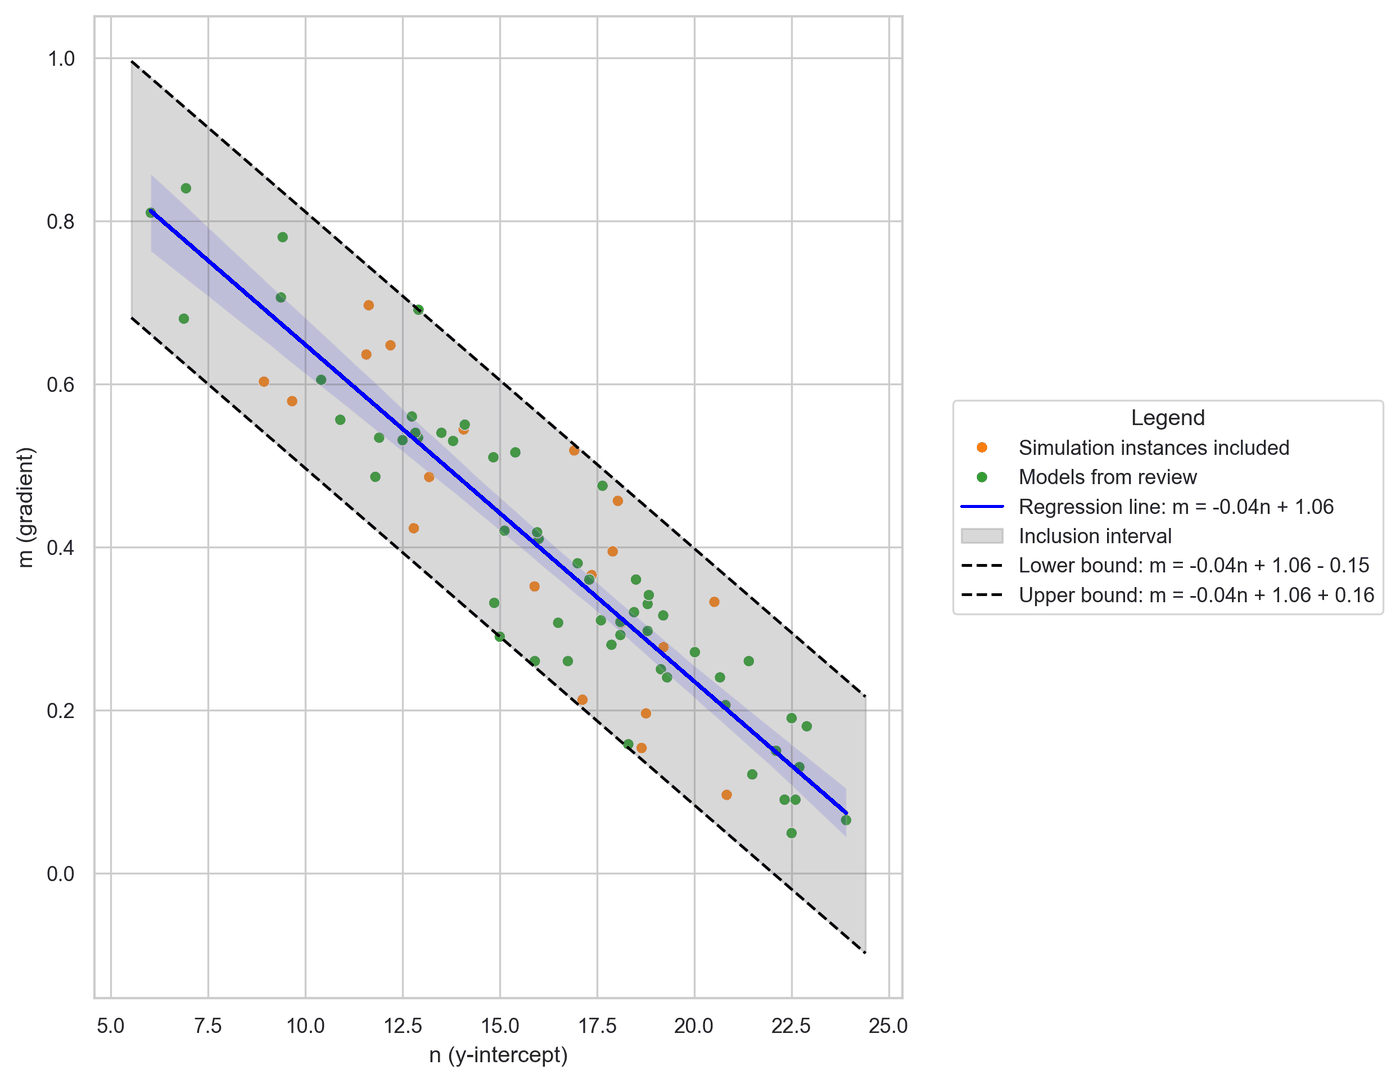

In [12]:
plot_out_dir = Path(RESULTS_DIRNAME) / "plots"
plot_out_dir.mkdir(parents=True, exist_ok=True)

mn_plot_path = parametric.plot_mn_filter(df_source="parametric", out_dir=str(plot_out_dir))
show_plot_output(mn_plot_path)


## WF1 custom parametric: execute parametric run and inspect output rows

This is the execution checkpoint: we run the full parametric plan and collect output rows.

With the lighter settings, one annual simulation of the sample model takes about 25-35 s when several run in parallel (8-9 s in EnergyPlus, the rest in preparing the model and reading the results). The run takes roughly `expected_runs x 35 s / PROCESSES`: about 4-5 minutes for 40 simulations with 6 processes.

Each simulation folder is kept, because the comfort screening reads its hourly `eplusout.csv`. `sim_files_extensions` deletes the other files once the results have been read, except `eplusmtr.csv`, a CSV file with the same meters that EnergyPlus writes alongside `eplusout.csv`; the cell deletes it after the run. Each folder then holds about 1 MB.

If row counts differ from expectations, inspect plan size and weather/model multipliers before continuing to analysis.

Key arguments used in this cell and why they matter:
- `out_dir`: output folder for generated artifacts and results.
- `df`: case plan dataframe executed in this run.
- `processes`: number of parallel processes for simulation runs.
- `keep_input`: whether generated input files are preserved.
- `keep_dirs`: whether per-run directories are preserved (required by the hourly screening).
- `sim_files_extensions` and `sim_files_policy`: keep only the CSV and ERR files of each simulation.
- The loop after the run deletes the duplicated meter files (`eplusmtr.csv`), which no cell reads.

Variables created in this cell:
- `outputs`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Compare returned row count with the expected number of plan combinations.
- Inspect the first rows to ensure objective columns are present and populated.

In [13]:
outputs = parametric.run_parametric_simulation(
    out_dir=RESULTS_DIRNAME,
    df=plan_df,
    processes=PROCESSES,
    keep_input=True,
    keep_dirs=True,
    sim_files_extensions=[".csv", ".err"],
    sim_files_policy="keep",
)
for meter_csv in Path(RESULTS_DIRNAME).rglob("eplusmtr.csv"):
    meter_csv.unlink()


  [info] simulation_summary updated for parametric after run_parametric_simulation.


### Reading the result

Review the row count and confirm it matches the expected combinations from your plan and EPW set.

We perform a quick sanity check on row counts and first records before post-processing, and check that the hourly outputs include the ASHRAE 55 running mean.

This lightweight preview catches missing columns or unexpected schema changes early, while context is still fresh. The screening below takes the running mean from the hourly outputs (`running_mean="auto"`); if the column were missing, accim would calculate an EN 16798-1 running mean from the outdoor temperature instead, without the ASHRAE 55 definition.

What to verify right after running this cell:
- Confirm row counts and first records look consistent with the execution settings.
- Check that the ASHRAE 55 running mean column is listed.
- Check the size of the results folder: about 1 MB per simulation.

In [14]:
print("Rows:", len(outputs), "| expected:", expected_runs)
print(outputs.head())

first_csv = Path(outputs["output_dir"].iloc[0]) / "eplusout.csv"
hourly_columns = pd.read_csv(first_csv, nrows=0).columns
running_mean_columns = [c for c in hourly_columns if "ASHRAE 55 Adaptive Model Running Average" in c]
print("Hourly columns:", len(hourly_columns) - 1)
print("ASHRAE 55 running mean:", running_mean_columns)
assert running_mean_columns, "The hourly outputs do not include the ASHRAE 55 running mean."

results_mb = sum(p.stat().st_size for p in Path(RESULTS_DIRNAME).rglob("*") if p.is_file()) / 1e6
print(f"Results folder: {results_mb:.1f} MB")


Rows: 40 | expected: 40
   Electricity:HVAC  Heating:Electricity  Cooling:Electricity  \
0      8.924086e+10         1.029398e+10         4.627243e+10   
1      1.091671e+11         7.457230e+09         6.886548e+10   
2      1.233165e+11         5.954763e+09         8.964649e+10   
3      8.179243e+10         1.199084e+10         4.667485e+10   
4      5.544345e+10         5.343431e+08         4.376693e+10   

   Annual mean operative temperature FLOOR_1_ZONE  \
0                                       25.658871   
1                                       23.794431   
2                                       22.039636   
3                                       25.054904   
4                                       24.660468   

   Annual mean operative temperature FLOOR_2_ZONE  \
0                                       24.595621   
1                                       23.133584   
2                                       21.666656   
3                                       24.241974   
4

## WF1 custom parametric: normalize datasets for cross-case comparison

In this stage we normalize outputs to make cross-case and cross-climate comparisons fairer.

Keep normalization choices consistent across workflows when preparing comparative figures or decision-support summaries.

Key arguments used in this cell and why they matter:
- `mode`: operation mode for the current method.
- `df_types`: dataset groups that should be normalized.

What to verify right after running this cell:
- Confirm normalization scope (`df_types`) matches the intended datasets.
- Check one or two normalized columns to verify value scaling behaves as expected.

In [15]:
parametric.set_building_floor_area(mode="all")
parametric.normalize_outputs(df_types=["parametric"])


  [info] Floor area calculation: total IDFs=1, representative IDFs loaded=1.
  [info] Floor area mapping coverage: 1/1 IDFs.
  [info] Building floor area: 185.81 m² (single IDF)
  [info] Normalized 3 energy columns in outputs_param_simulation.


## WF1 custom parametric: collect the result columns used in the plots

This cell identifies the columns of the results table used by the plotting cells.

The main energy output is the annual HVAC electricity (`Electricity:HVAC`), as in the paper; heating and cooling electricity are additional outputs.

Variables created in this cell:
- `norm_df`: reused in subsequent workflow blocks.
- `numeric_cols`: reused in subsequent workflow blocks.
- `energy_cols`: reused in subsequent workflow blocks.
- `x_param`: reused in subsequent workflow blocks.
- `y_param`: reused in subsequent workflow blocks.
- `main_energy_col`: reused in subsequent workflow blocks.
- `heating_energy_col`: reused in subsequent workflow blocks.
- `cooling_energy_col`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that the three energy columns are found.

In [16]:
norm_df = parametric.outputs_param_simulation.copy()
numeric_cols = [c for c in norm_df.columns if pd.api.types.is_numeric_dtype(norm_df[c])]
energy_cols = [c for c in numeric_cols if any(meter in c for meter in meter_names)]
x_param = "CustAST_m"
y_param = "CustAST_n"
main_energy_col = next(c for c in energy_cols if "Electricity:HVAC" in c)
heating_energy_col = next(c for c in energy_cols if "Heating:Electricity" in c)
cooling_energy_col = next(c for c in energy_cols if "Cooling:Electricity" in c)
print(main_energy_col, "|", heating_energy_col, "|", cooling_energy_col)


Electricity:HVAC_kWh/m2 | Heating:Electricity_kWh/m2 | Cooling:Electricity_kWh/m2


## WF1 custom parametric: generate categorical boxplots for key metrics

We start the visualization stage with categorical boxplots of the heating and cooling electricity of all samples, coloured by weather file.

This view is useful for quickly spotting median shifts and variability differences between climates.

Key arguments used in this cell and why they matter:
- `df_source`: defines this setting for the current call.
- `y_vars`: outputs drawn side by side.
- `col`: facet column used in plotting.
- `hue`: field used to color plot traces.
- `out_dir`: output folder for generated artifacts and results.
- `normalize_per_m2`: whether results are normalized by floor area (already done by `normalize_outputs`).
- `show_points`: whether individual points are overlaid on summary plots.
- `sharey`: whether facets share the same y-axis scale.
- `height`: height of each plotting panel.
- `aspect`: aspect ratio of each plotting panel.

Variables created in this cell:
- `fig`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Open exported figures and verify labels, grouping, and normalization settings.
- Confirm output files were saved in the expected folder.

  Categorical boxplot saved: wf1_parametric_custom_results\plots\plot_categorical_boxplots_parametric__hue_epw.png


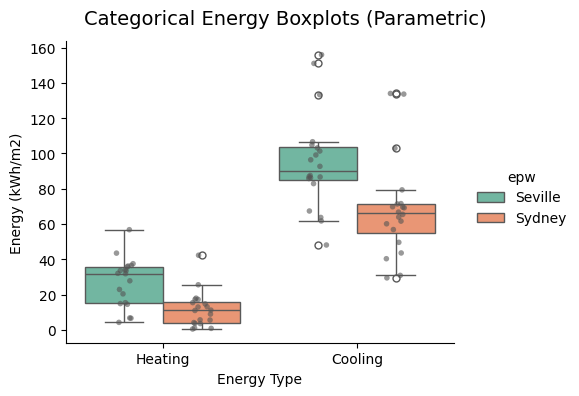

In [17]:
fig = parametric.plot_categorical_boxplots(
    df_source="parametric",
    y_vars=[heating_energy_col, cooling_energy_col],
    col=None,
    hue="epw",
    out_dir=str(plot_out_dir),
    normalize_per_m2=False,
    show_points=True,
    sharey=True,
    height=4.0,
    aspect=1.2,
)
show_plot_output(fig)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

This cell builds scatter relationships between parameters and key outputs.

Scatter views help detect monotonic trends, nonlinear regions, and potential interaction patterns worth deeper analysis.

Key arguments used in this cell and why they matter:
- `x`: x-axis variable used in plotting.
- `y`: y-axis variable used in plotting.
- `df_source`: defines this setting for the current call.
- `hue`: field used to color plot traces.
- `style`: field used to style plot traces.
- `add_trend`: defines this setting for the current call.
- `out_dir`: output folder for generated artifacts and results.
- `normalize_per_m2`: whether results are normalized by floor area.

Variables created in this cell:
- `fig_scatter`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Open exported figures and verify labels, grouping, and normalization settings.
- Confirm output files were saved in the expected folder.

  Parametric scatter plot saved: wf1_parametric_custom_results\plots\plot_parametric_scatter_parametric_CustAST_m_vs_Electricity_HVAC_kWh_m2.png


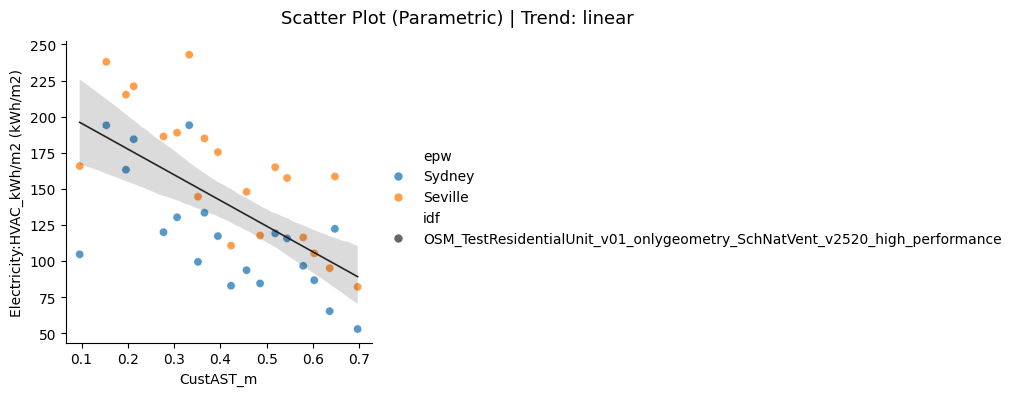

In [18]:
fig_scatter = parametric.plot_parametric_scatter(
    x=x_param,
    y=main_energy_col,
    df_source="parametric",
    hue="epw",
    style="idf",
    add_trend="linear",
    out_dir=str(plot_out_dir),
    normalize_per_m2=False,
)
show_plot_output(fig_scatter)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## WF1 custom parametric: generate 2D density/hexbin views

Here we build 2D density/hexbin plots to visualize concentration patterns in parameter-output space.

This view is useful for identifying dense performance regions and sparse outliers that may deserve targeted checks.

Key arguments used in this cell and why they matter:
- `x`: x-axis variable used in plotting.
- `y`: y-axis variable used in plotting.
- `kind`: plot kind (for example violin or hexbin).
- `df_source`: defines this setting for the current call.
- `col`: facet column used in plotting.
- `out_dir`: output folder for generated artifacts and results.
- `normalize_per_m2`: whether results are normalized by floor area.

Variables created in this cell:
- `fig_density_2d`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Open exported figures and verify labels, grouping, and normalization settings.
- Confirm output files were saved in the expected folder.

  Parametric 2D density plot saved: wf1_parametric_custom_results\plots\plot_parametric_density2d_hexbin_parametric_CustAST_m_vs_Electricity_HVAC_kWh_m2.png


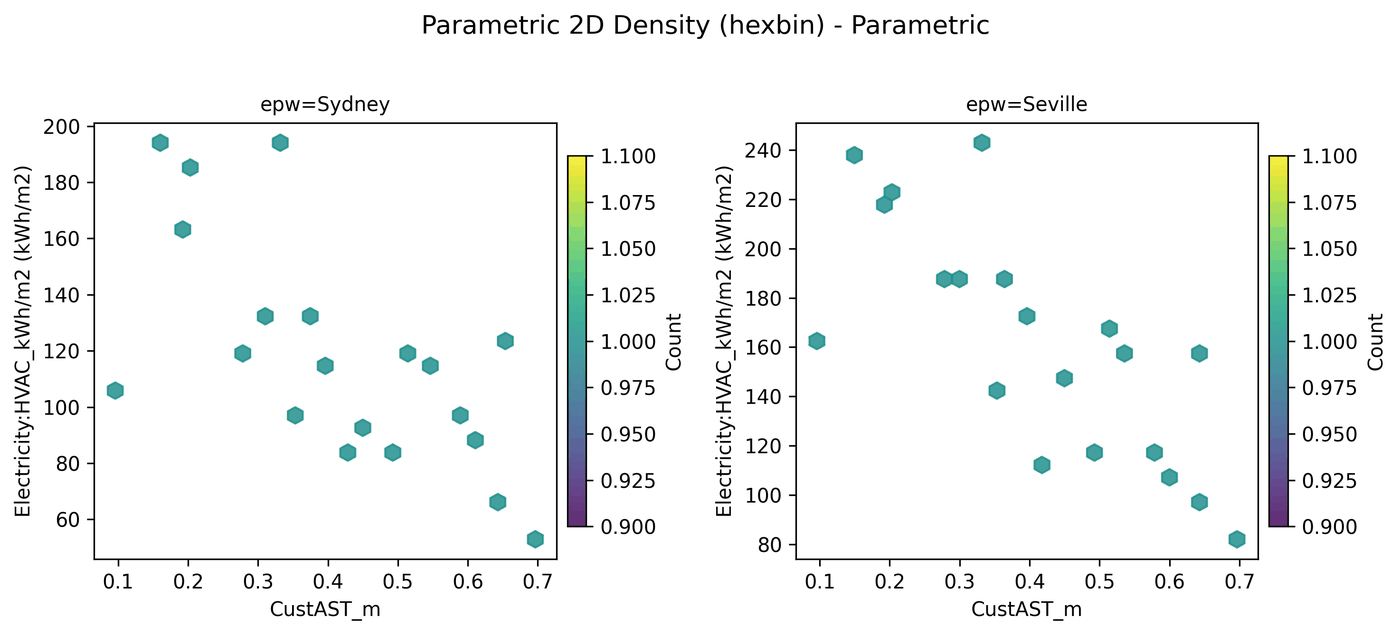

In [19]:
fig_density_2d = parametric.plot_parametric_density_2d(
    x=x_param,
    y=main_energy_col,
    kind="hexbin",
    df_source="parametric",
    col="epw",
    out_dir=str(plot_out_dir),
    normalize_per_m2=False,
)
show_plot_output(fig_density_2d)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## WF1 custom parametric: generate contour maps over the m-n plane

In this section we draw the annual HVAC electricity over the plane of `m` and `n`, one panel per weather file.

The samples are scattered, so the contours are interpolated on a triangulation of the sampled pairs; they only cover the band, because no pair was drawn outside it. With few samples, read the contours as a trend.

Key arguments used in this cell and why they matter:
- `x`: x-axis variable used in plotting.
- `y`: y-axis variable used in plotting.
- `z`: z-axis or color-value variable used in plotting.
- `df_source`: defines this setting for the current call.
- `col`: facet column used in plotting.
- `out_dir`: output folder for generated artifacts and results.
- `normalize_per_m2`: whether results are normalized by floor area.

Variables created in this cell:
- `fig_contour`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Open exported figures and verify labels, grouping, and normalization settings.
- Confirm output files were saved in the expected folder.

  Parametric contour plot saved: wf1_parametric_custom_results\plots\plot_parametric_contour_parametric_Electricity_HVAC_kWh_m2_by_CustAST_m_CustAST_n.png


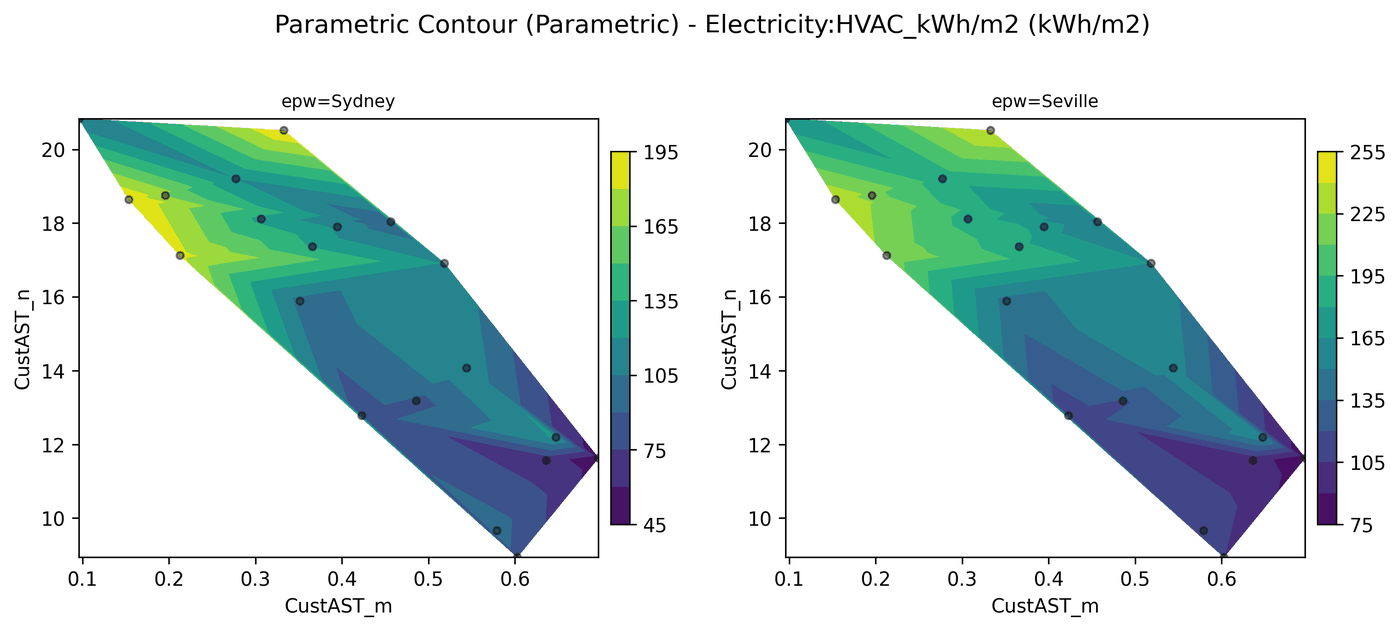

In [20]:
fig_contour = parametric.plot_parametric_contour(
    x=x_param,
    y=y_param,
    z=main_energy_col,
    df_source="parametric",
    col="epw",
    out_dir=str(plot_out_dir),
    normalize_per_m2=False,
)
show_plot_output(fig_contour)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

This cell generates distribution plots for objective variables to compare spread and shape.

Distribution views complement Pareto plots by showing variability and overlap between parameter groups.

Key arguments used in this cell and why they matter:
- `x`: x-axis variable used in plotting.
- `y_vars`: list of output variables to plot.
- `kind`: plot kind (for example violin or hexbin).
- `df_source`: defines this setting for the current call.
- `hue`: field used to color plot traces.
- `out_dir`: output folder for generated artifacts and results.
- `normalize_per_m2`: whether results are normalized by floor area.
- `show_points`: whether individual points are overlaid on summary plots.

Variables created in this cell:
- `fig_distributions`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Open exported figures and verify labels, grouping, and normalization settings.
- Confirm output files were saved in the expected folder.

site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#1f77b4'` for the same effect.

  func(*plot_args, **plot_kwargs)


  Parametric violin plot saved: wf1_parametric_custom_results\plots\plot_parametric_violin_parametric_Electricity_HVAC_kWh_m2_by_epw.png


site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#1f77b4'` for the same effect.

  func(*plot_args, **plot_kwargs)


  Parametric violin plot saved: wf1_parametric_custom_results\plots\plot_parametric_violin_parametric_Heating_Electricity_kWh_m2_by_epw.png


  Parametric violin plot saved: wf1_parametric_custom_results\plots\plot_parametric_violin_parametric_Cooling_Electricity_kWh_m2_by_epw.png


site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#1f77b4'` for the same effect.

  func(*plot_args, **plot_kwargs)


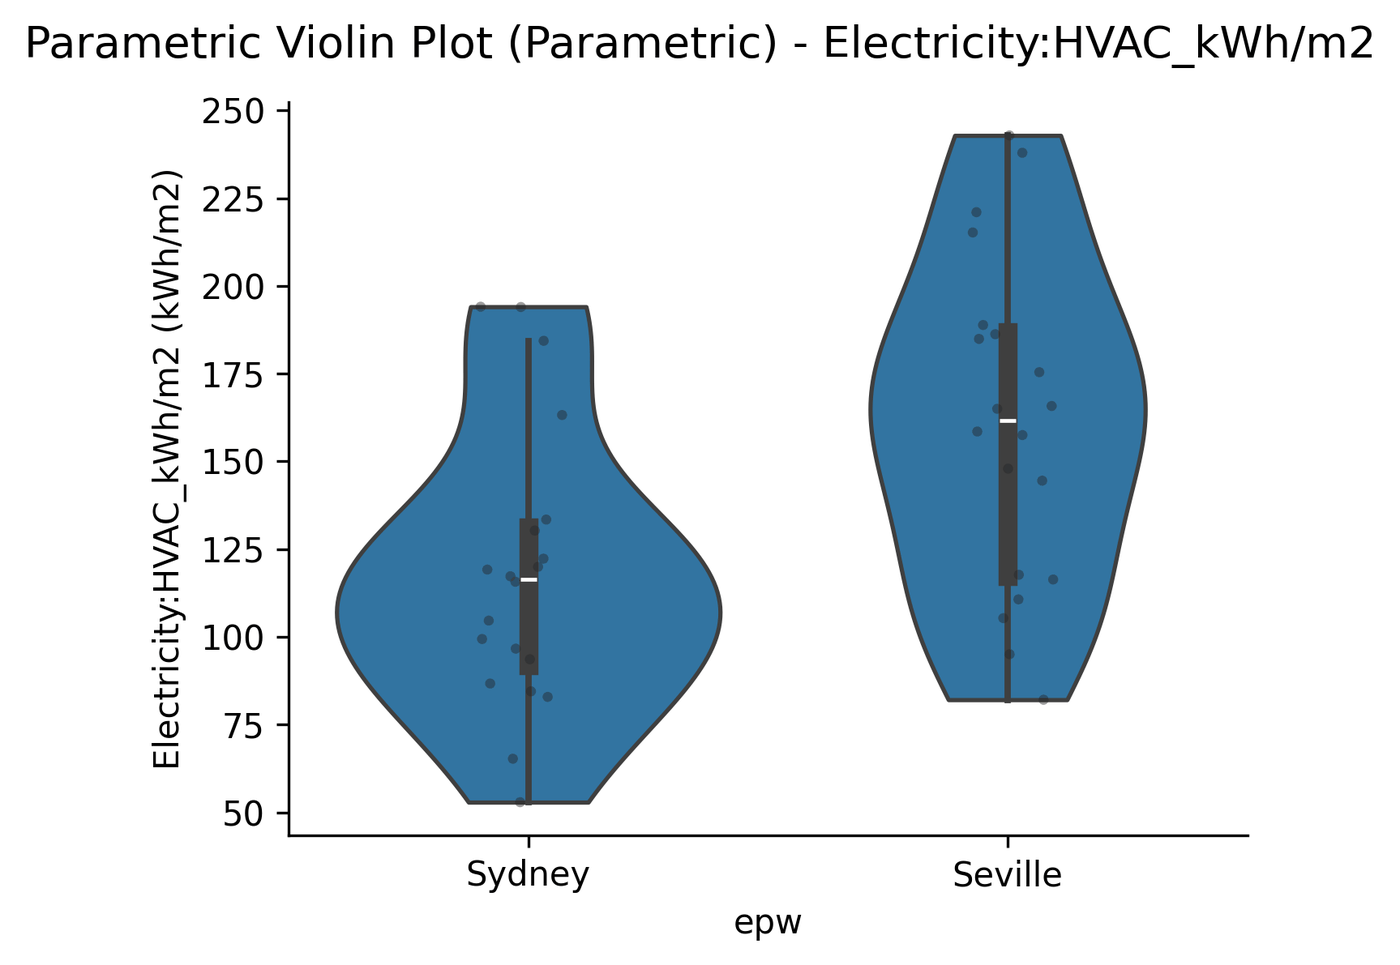

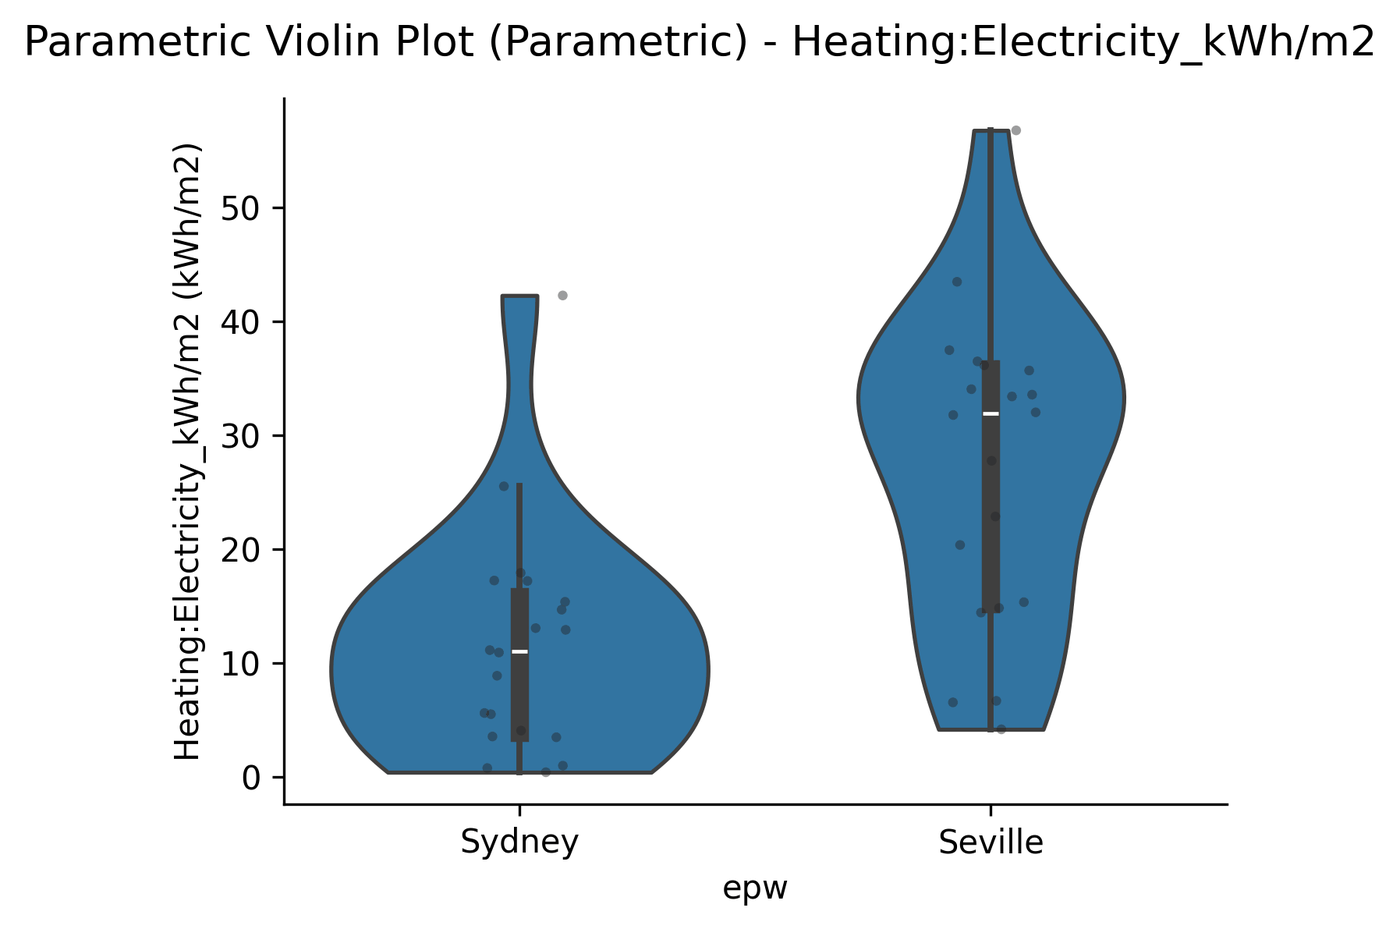

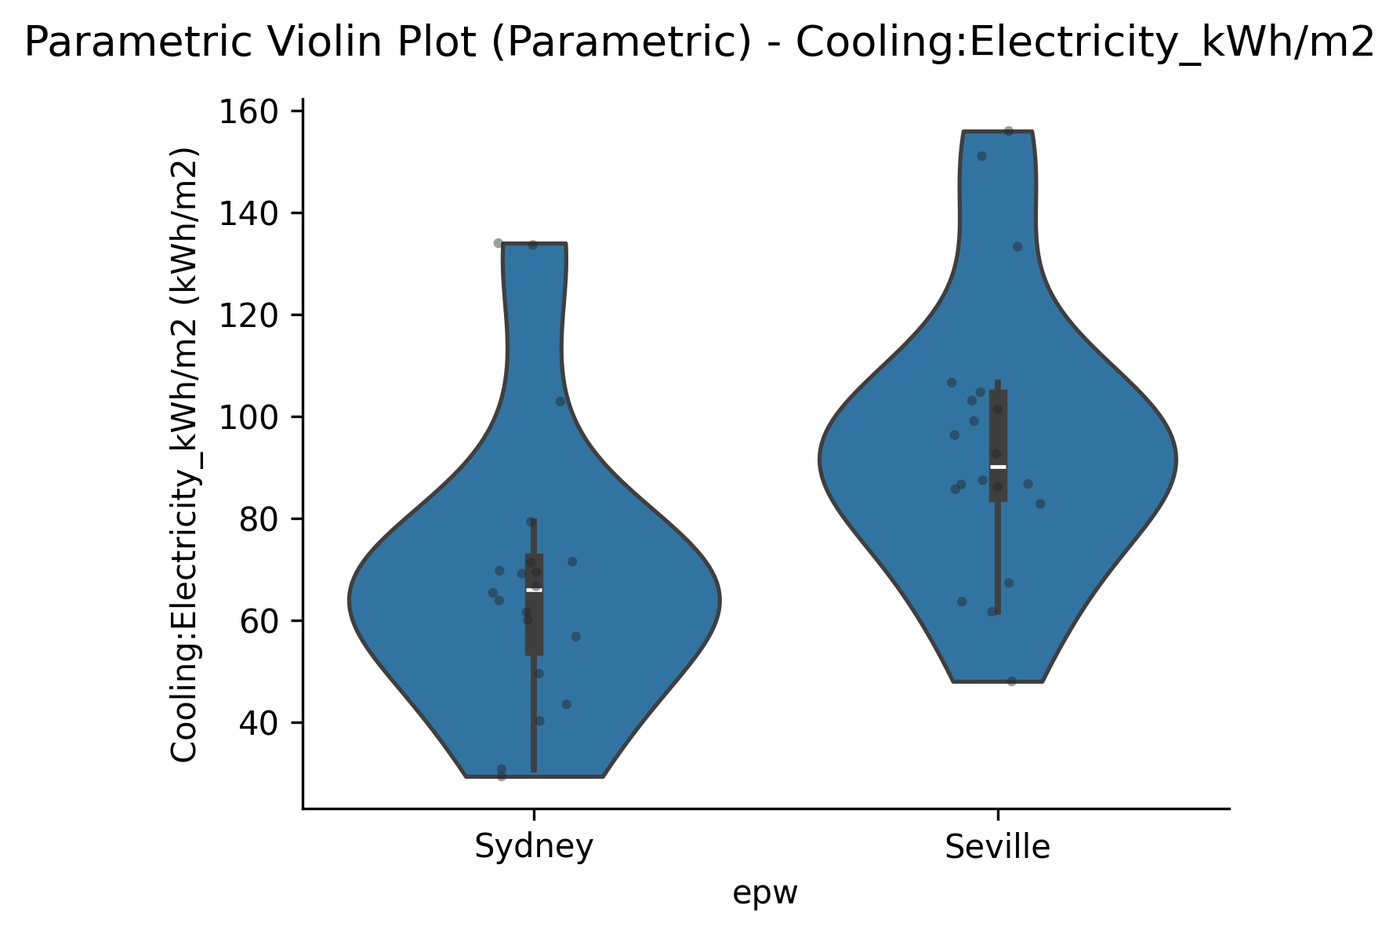

In [21]:
fig_distributions = parametric.plot_parametric_distributions(
    x="epw",
    y_vars=[main_energy_col, heating_energy_col, cooling_energy_col],
    kind="violin",
    df_source="parametric",
    hue="idf",
    out_dir=str(plot_out_dir),
    normalize_per_m2=False,
    show_points=True,
)
show_plot_output(fig_distributions)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

This block adds ECDF plots to compare output distributions across scenarios.

ECDF curves are especially useful when comparing the full distribution rather than only mean or median behavior.

Key arguments used in this cell and why they matter:
- `x`: x-axis variable used in plotting.
- `df_source`: defines this setting for the current call.
- `hue`: field used to color plot traces.
- `out_dir`: output folder for generated artifacts and results.
- `normalize_per_m2`: whether results are normalized by floor area.

Variables created in this cell:
- `fig_ecdf`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Open exported figures and verify labels, grouping, and normalization settings.
- Confirm output files were saved in the expected folder.

  Parametric ECDF plot saved: wf1_parametric_custom_results\plots\plot_parametric_ecdf_parametric_Electricity_HVAC_kWh_m2.png


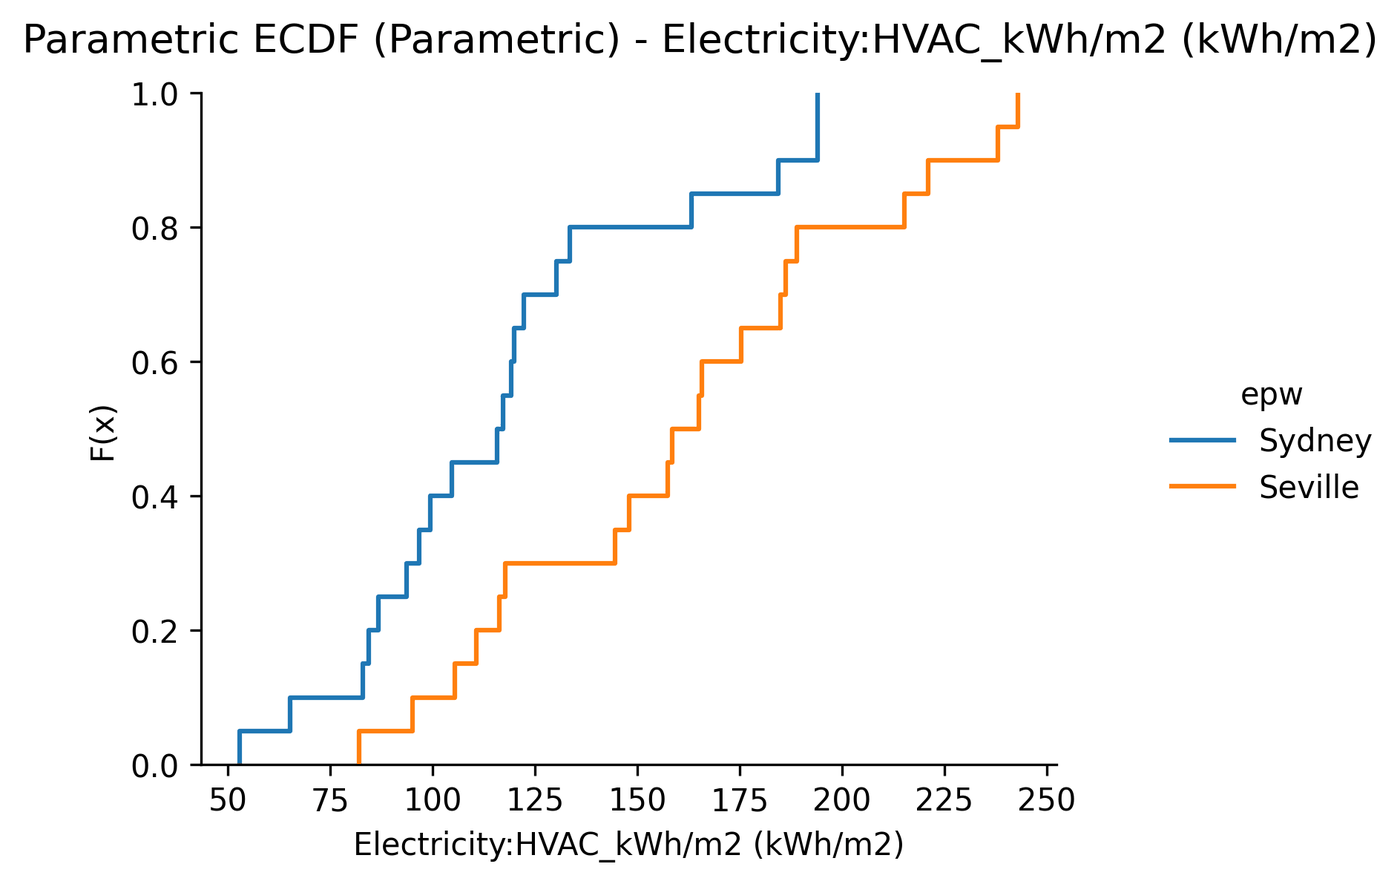

In [22]:
fig_ecdf = parametric.plot_parametric_ecdf(
    x=main_energy_col,
    df_source="parametric",
    hue="epw",
    out_dir=str(plot_out_dir),
    normalize_per_m2=False,
)
show_plot_output(fig_ecdf)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## WF1 custom parametric: generate radar comparison across grouped solutions

Here we build radar charts to compare grouped solutions across multiple metrics.

Radar views are helpful for communication when multiple performance dimensions must be interpreted simultaneously.

Key arguments used in this cell and why they matter:
- `metrics`: metrics included in the radar plot.
- `group_by`: field used to group traces in the radar plot.
- `df_source`: defines this setting for the current call.
- `out_dir`: output folder for generated artifacts and results.
- `normalize_per_m2`: whether results are normalized by floor area.
- `image_paths`: defines this setting for the current call.

Variables created in this cell:
- `radar_metrics`: reused in subsequent workflow blocks.
- `fig_radar`: reused in subsequent workflow blocks.
- `radar_plot_path`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Open exported figures and verify labels, grouping, and normalization settings.
- Confirm output files were saved in the expected folder.

  Parametric radar plot saved: wf1_parametric_custom_results\plots\plot_parametric_radar_parametric_group_epw.png


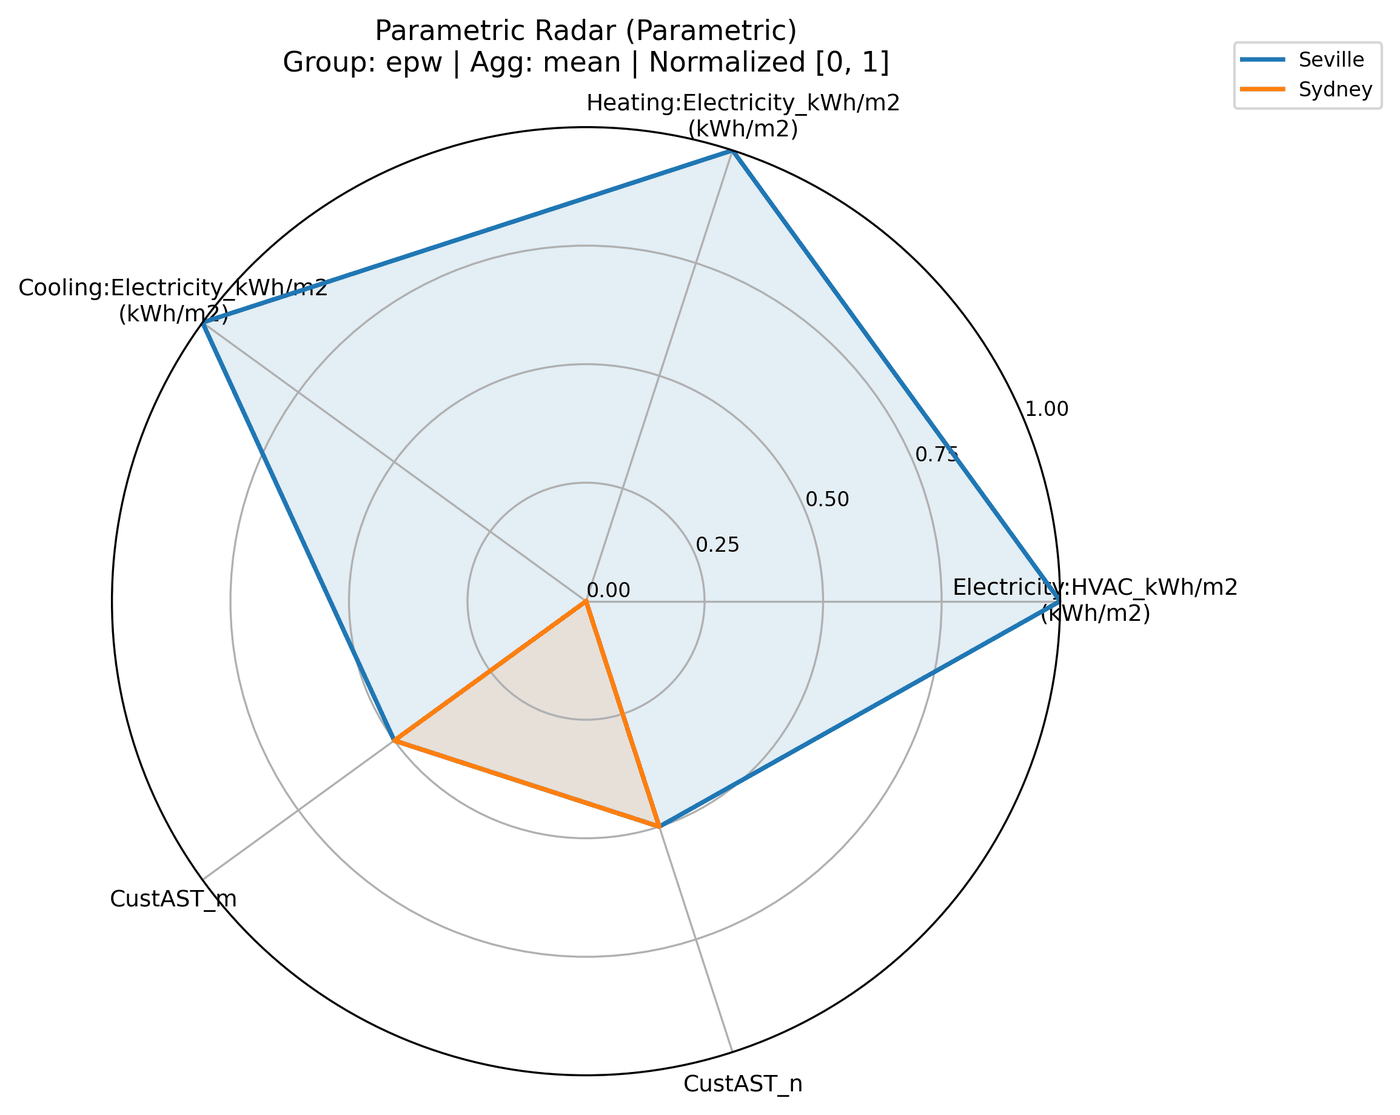

,epw,Electricity:HVAC_kWh/m2,Heating:Electricity_kWh/m2,Cooling:Electricity_kWh/m2,CustAST_m,CustAST_n
0,Seville,160.940765,27.196838,95.064745,0.413735,15.66739
1,Sydney,118.008148,11.590971,68.486566,0.413735,15.66739


In [23]:
radar_metrics = [main_energy_col, heating_energy_col, cooling_energy_col, x_param, y_param]
fig_radar = parametric.plot_parametric_radar(
    metrics=radar_metrics,
    group_by="epw",
    df_source="parametric",
    out_dir=str(plot_out_dir),
    normalize_per_m2=False,
)
radar_plot_path = plot_out_dir / "plot_parametric_radar_parametric_group_epw.png"
show_plot_output(fig_radar, image_paths=radar_plot_path)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## WF1 custom parametric: screen the evaluations against ASHRAE 55

The comfort criterion of the custom model is part of the control, but it can be compared after simulation with a published criterion. Here each evaluation is screened against the ASHRAE 55 adaptive model with 80 % acceptability, from its hourly outputs (nothing is simulated again):
- band: 0.31 Trm + 17.8 °C ± 3.5 K, where Trm is the running mean outdoor temperature reported by EnergyPlus (`running_mean="auto"`);
- outside the applicability range of Trm (10-33.5 °C), the limits of the nearest applicable Trm are kept (`applicability="clip"`, a horizontal extension);
- an evaluation meets the criterion when at most 5 % of the hours of the year are outside the band (`max_share_outside=0.05`); otherwise it is "too warm" or "too cool", depending on the side of the band with most of those hours.

The screening is applied to the custom model only. Screening the predefined models would compare comfort standards with each other, and the aPMV controls have no temperature setpoints.

Key arguments used in this cell and why they matter:
- `df_source`: `"parametric"` reads the hourly CSV of every evaluation of the results table, one at a time.
- `comfort_standard`, `categories` and `outcome_category`: ASHRAE 55, 80 % acceptability.
- `running_mean`, `applicability` and `max_share_outside`: as described above.

Variables created in this cell:
- `ASHRAE55_SCREENING`: reused in subsequent workflow blocks.
- `indicators`: one row per evaluation, also stored in `parametric.hourly_indicators`.
- `summary_cols`: reused in subsequent workflow blocks.
- `cities`: names of the weather files, used to order the panels.

What to verify right after running this cell:
- Check how many evaluations meet the criterion, or are too warm or too cool, in each climate.

In [24]:
ASHRAE55_SCREENING = dict(
    comfort_standard="ASHRAE55",
    categories=["80"],
    outcome_category="80",
    running_mean="auto",
    applicability="clip",
    max_share_outside=0.05,
)
indicators = parametric.compute_hourly_indicators(df_source="parametric", **ASHRAE55_SCREENING)

summary_cols = ["epw", "CustAST_m", "CustAST_n", "CustAST_ASToffset", "CustAST_ASTaul",
                "E_HVAC", "T_mean", "share_outside_80", "comfort_outcome"]
cities = [Path(epw).stem for epw in epw_list]
print(indicators.attrs["comfort"])
display(indicators.groupby("epw")["comfort_outcome"].value_counts().unstack(fill_value=0))
indicators[summary_cols].head()


  [compute_hourly_indicators] 40/40 simulations
{'standard': 'ASHRAE55', 'categories': ['80'], 'applicability': 'clip', 'outcome_category': '80', 'max_share_outside': 0.05}


comfort_outcome,meets,too cool,too warm
epw,,,
Seville,6,2,12
Sydney,12,0,8


,epw,CustAST_m,CustAST_n,CustAST_ASToffset,CustAST_ASTaul,E_HVAC,T_mean,share_outside_80,comfort_outcome
0,Sydney,0.365550,17.361834,2.221117,39.663742,133.413970,25.127246,0.000000,meets
1,Sydney,0.195870,18.757659,1.900028,32.203100,163.203451,23.464008,0.000000,meets
2,Sydney,0.212666,17.125905,1.410888,30.916303,184.356699,21.853146,0.000114,meets
3,Sydney,0.647343,12.190559,1.665142,36.762304,122.278667,24.648439,0.024087,meets
4,Sydney,0.422952,12.789691,4.693285,29.714991,82.887261,23.952963,0.016096,meets


### Reading the result

`E_HVAC` is the annual HVAC electricity in kWh/m2 (from the hourly meter), `T_mean` the annual mean operative temperature of the zones, and `share_outside_80` the share of hours outside the band (0-1). `share_above_80` and `share_below_80` tell on which side the hours outside the band are.

## WF1 custom parametric: parameters and screening outcome in a scatter matrix

The scatter matrix relates the four parameters, the HVAC electricity and the share of hours outside the ASHRAE 55 band, one figure per climate, as in the figure of Example 2 of the paper. The lower panels and the histograms are coloured by the screening outcome; the upper panels are coloured by the annual mean operative temperature.

Below each figure, a table gives the Spearman rank correlation of each parameter with the HVAC electricity, the annual mean operative temperature and the share of hours outside the band, over all the evaluations of the climate. Spearman correlation measures monotonic associations without assuming linearity. The `summary` of the figure gives the same coefficients within each outcome group.

Key arguments used in this cell and why they matter:
- `columns`: the columns of `indicators` drawn in the matrix.
- `hue`, `hue_labels`, `hue_order`, `palette`: grouping by `comfort_outcome`.
- `upper`, `color_by`: upper panels as scatter plots coloured by `T_mean` (`upper="spearman"` writes the correlation coefficients instead).
- `diag`: stacked histograms per outcome.
- `percent_columns`: shares drawn as percentages.
- `data_filter`: one climate per figure.

Variables created in this cell:
- `outcome_labels`: reused in subsequent workflow blocks.
- `outcome_palette`: reused in subsequent workflow blocks.
- `matrix_columns`: reused in subsequent workflow blocks.
- `matrix_labels`: reused in subsequent workflow blocks.
- `fig_matrix`: the figure of the last climate.
- `spearman`: the correlation table of the last climate.

What to verify right after running this cell:
- Look for the parameters that separate the outcomes (for example, the intercept `n` for evaluations that are too warm or too cool).

  plot_results_scatter_matrix saved: wf1_parametric_custom_results\plots\plot_results_scatter_matrix_sydney.png


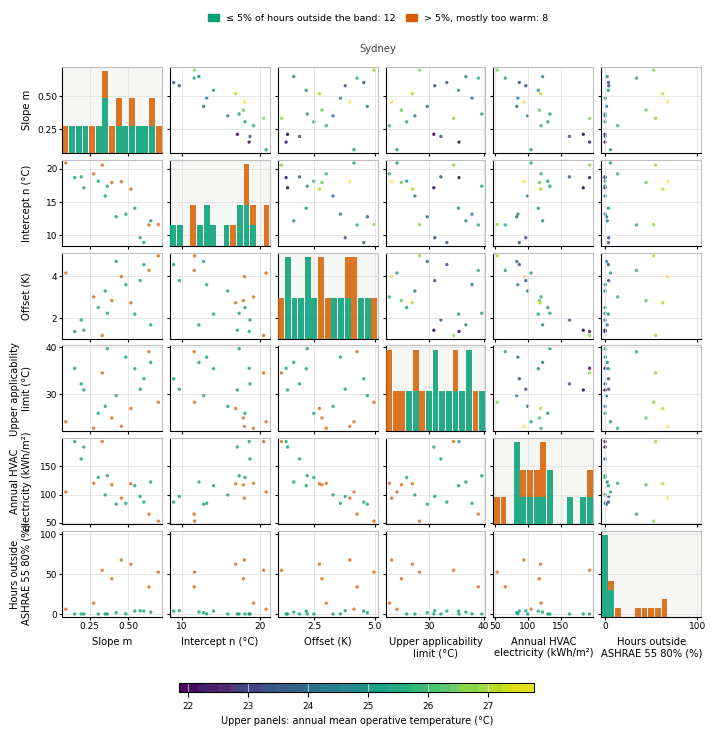

,E_HVAC,T_mean,share_outside_80
CustAST_m,-0.64,0.18,0.40
CustAST_n,0.66,0.28,-0.05
CustAST_ASToffset,-0.93,0.17,0.34
CustAST_ASTaul,0.09,-0.39,-0.37


  plot_results_scatter_matrix saved: wf1_parametric_custom_results\plots\plot_results_scatter_matrix_seville.png


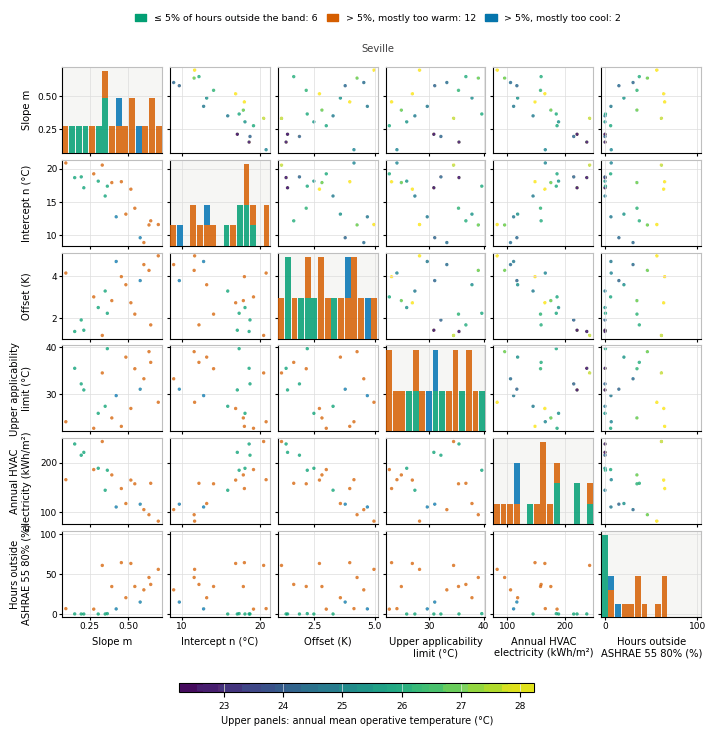

,E_HVAC,T_mean,share_outside_80
CustAST_m,-0.79,0.47,0.65
CustAST_n,0.83,-0.00,-0.27
CustAST_ASToffset,-0.85,0.14,0.23
CustAST_ASTaul,-0.08,-0.14,0.02


In [25]:
outcome_labels = {
    "meets": "≤ 5% of hours outside the band",
    "too warm": "> 5%, mostly too warm",
    "too cool": "> 5%, mostly too cool",
}
outcome_palette = {
    outcome_labels["meets"]: "#009E73",
    outcome_labels["too warm"]: "#D55E00",
    outcome_labels["too cool"]: "#0072B2",
}
matrix_columns = ["CustAST_m", "CustAST_n", "CustAST_ASToffset", "CustAST_ASTaul", "E_HVAC", "share_outside_80"]
matrix_labels = {
    "CustAST_m": "Slope m",
    "CustAST_n": "Intercept n (°C)",
    "CustAST_ASToffset": "Offset (K)",
    "CustAST_ASTaul": "Upper applicability\nlimit (°C)",
    "E_HVAC": "Annual HVAC\nelectricity (kWh/m²)",
    "share_outside_80": "Hours outside\nASHRAE 55 80% (%)",
}

for city in cities:
    fig_matrix = parametric.plot_results_scatter_matrix(
        matrix_columns,
        df=indicators,
        hue="comfort_outcome",
        hue_labels=outcome_labels,
        hue_order=list(outcome_labels.values()),
        palette=outcome_palette,
        upper="scatter",
        color_by="T_mean",
        diag="stacked",
        percent_columns=["share_outside_80"],
        color_label="Upper panels: annual mean operative temperature (°C)",
        labels=matrix_labels,
        bins=15,
        title=city,
        data_filter={"include": {"epw": {"contains": city}}},
        out_dir=str(plot_out_dir),
        filename=f"plot_results_scatter_matrix_{city.lower()}.png",
    )
    show_plot_output(fig_matrix)
    city_rows = indicators[indicators["epw"].str.contains(city)]
    spearman = city_rows[matrix_columns + ["T_mean"]].corr(method="spearman")
    display(spearman.loc[list(accis_parameters), ["E_HVAC", "T_mean", "share_outside_80"]].round(2))


### Reading the result

Each point is an evaluation. In the tables, values close to +1 or -1 mean that the output rises or falls steadily with the parameter; with few evaluations, the coefficients are uncertain.

## WF1 custom parametric: plot HVAC electricity against the hours outside the band

The screening plot draws every evaluation with its HVAC electricity and its share of hours outside the band, one panel per climate. The dashed line marks the 5 % tolerance, and a ring marks the lowest HVAC electricity among the evaluations that meet it.

Key arguments used in this cell and why they matter:
- `x`, `y`, `color`: HVAC electricity, share of hours outside the band and annual mean operative temperature.
- `col`: one panel per weather file.
- `threshold`: tolerance on the share of hours outside the band (0.05 = 5 %).
- `best_format`, `best_legend_label`: label of the lowest HVAC electricity within the tolerance.

Variables created in this cell:
- `fig_screening`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Compare the lowest HVAC electricity of all evaluations with the lowest among those that meet the tolerance.

  plot_comfort_screening saved: wf1_parametric_custom_results\plots\plot_comfort_screening.png


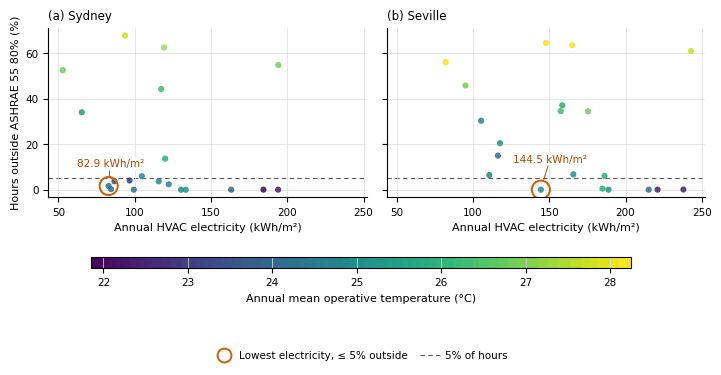

,row,col,n,n_meeting,best_x,best_y,best_index
0,all,Sydney,20,12,82.887261,0.016096,4
1,all,Seville,20,6,144.506467,0.000000,27


In [26]:
fig_screening = parametric.plot_comfort_screening(
    df=indicators,
    x="E_HVAC",
    y="share_outside_80",
    color="T_mean",
    col="epw",
    col_order=cities,
    threshold=0.05,
    xlabel="Annual HVAC electricity (kWh/m²)",
    ylabel="Hours outside ASHRAE 55 80% (%)",
    color_label="Annual mean operative temperature (°C)",
    best_format="{x:.1f} kWh/m²",
    best_legend_label="Lowest electricity, ≤ 5% outside",
    out_dir=str(plot_out_dir),
    filename="plot_comfort_screening.png",
)
show_plot_output(fig_screening)
display(fig_screening.summary)


### Reading the result

The summary lists, for each panel, the number of evaluations, how many meet the tolerance and the best evaluation among them. If no evaluation meets the tolerance in a climate, there is no ring in its panel.

## WF1 custom parametric: hourly comfort chart of two selected evaluations

Finally, we read the hourly outputs of two evaluations per climate (the lowest HVAC electricity of all, and the lowest among those that meet the tolerance) and draw their hourly operative temperature against the running mean, with the limits of the ASHRAE 55 80 % band. Only these simulations are loaded hourly, so the dataframe stays small.

Key arguments used in this cell and why they matter:
- `simulation_indices`: rows of the results table expanded to hourly values.
- `output_columns`: hourly columns read from the CSV files (names or substrings).
- `skip_confirmation`: skips interactive confirmation prompts.
- `row`, `col`: one row per selection and one column per weather file.
- `comfort_standard`, `category`, `applicability`: the band of the screening.

Variables created in this cell:
- `selected`: reused in subsequent workflow blocks.
- `hourly_selected`: reused in subsequent workflow blocks.
- `fig_comfort`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Check that the hours of the evaluation that meets the tolerance stay within the dashed limits.

,selection,epw,CustAST_m,CustAST_n,CustAST_ASToffset,CustAST_ASTaul,E_HVAC,T_mean,share_outside_80,comfort_outcome
0,Lowest HVAC electricity,Seville,0.696498,11.631260,4.964017,28.308031,82.086663,28.136109,0.560502,too warm
1,"Lowest HVAC electricity, ≤ 5% outside",Seville,0.351522,15.893065,3.282060,27.455223,144.506467,24.853658,0.000000,meets
2,Lowest HVAC electricity,Sydney,0.696498,11.631260,4.964017,28.308031,52.895716,26.798639,0.525913,too warm
3,"Lowest HVAC electricity, ≤ 5% outside",Sydney,0.422952,12.789691,4.693285,29.714991,82.887261,23.952963,0.016096,meets


[get_hourly_df_parametric] Expanding...
  Simulations selected : 2
  Hourly steps per sim : 8760
  Hourly output columns: 3  -> ['FLOOR_1_ZONE:Zone Operative Temperature [C](Hourly)', 'FLOOR_2_ZONE:Zone Operative Temperature [C](Hourly)', 'FLOOR_1 RESIDENTIAL LIVING OCCUPANTS:Zone Thermal Comfort ASHRAE 55 Adaptive Model Running Average Outdoor Air Temperature [C](Hourly)']
  Source              : csv
  Expanded shape       : ~17,520 rows x 11 cols
  Approx. memory       : ~1.5 MB
[get_hourly_df_parametric] Expanding...
  Simulations selected : 2
  Hourly steps per sim : 8760
  Hourly output columns: 3  -> ['FLOOR_1_ZONE:Zone Operative Temperature [C](Hourly)', 'FLOOR_2_ZONE:Zone Operative Temperature [C](Hourly)', 'FLOOR_1 RESIDENTIAL LIVING OCCUPANTS:Zone Thermal Comfort ASHRAE 55 Adaptive Model Running Average Outdoor Air Temperature [C](Hourly)']
  Source              : csv
  Expanded shape       : ~17,520 rows x 11 cols
  Approx. memory       : ~1.5 MB


  plot_adaptive_comfort_chart saved: wf1_parametric_custom_results\plots\plot_adaptive_comfort_chart_selected.png


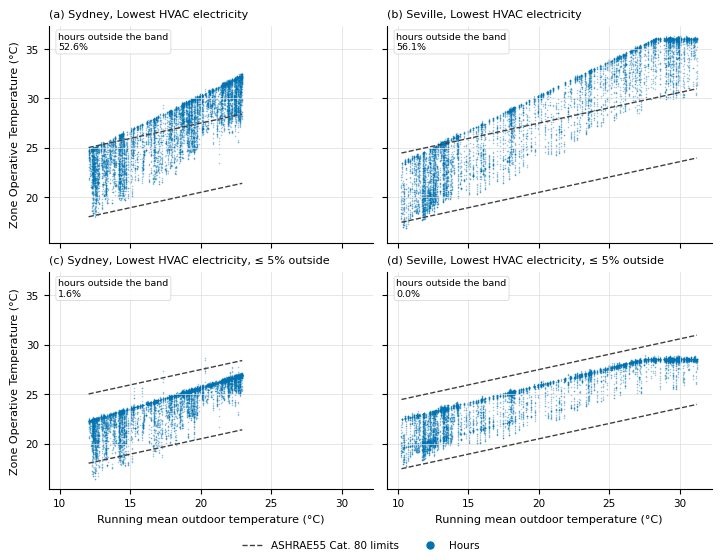

In [27]:
selected_rows = []
for epw_value, group in indicators.groupby("epw"):
    selected_rows.append(group.loc[[group["E_HVAC"].idxmin()]].assign(selection="Lowest HVAC electricity"))
    meets = group[group["comfort_outcome"] == "meets"]
    if not meets.empty:
        selected_rows.append(
            meets.loc[[meets["E_HVAC"].idxmin()]].assign(selection="Lowest HVAC electricity, ≤ 5% outside")
        )
selected = pd.concat(selected_rows, ignore_index=True)
display(selected[["selection"] + summary_cols])

results_table = parametric.outputs_param_simulation
hourly_frames = []
for label, rows in selected.groupby("selection", sort=False):
    indices = results_table.index[results_table["output_dir"].isin(rows["output_dir"])].tolist()
    parametric.get_hourly_df_parametric(
        simulation_indices=indices,
        output_columns=["Zone Operative Temperature", "ASHRAE 55 Adaptive Model Running Average"],
        skip_confirmation=True,
    )
    hourly_frames.append(parametric.outputs_param_simulation_hourly.assign(selection=label))
hourly_selected = pd.concat(hourly_frames, ignore_index=True)

fig_comfort = parametric.plot_adaptive_comfort_chart(
    df=hourly_selected,
    row="selection",
    col="epw",
    col_order=cities,
    comfort_standard="ASHRAE55",
    category="80",
    applicability="clip",
    out_dir=str(plot_out_dir),
    filename="plot_adaptive_comfort_chart_selected.png",
)
show_plot_output(fig_comfort)


### Reading the result

Points above the upper dashed line are too warm and points below the lower one too cool. The annotation of each panel gives the share of hours outside the band, the same value as `share_outside_80` in `indicators`.